# Австралия — анализ благополучия и долгосрочных перспектив развития

**Период исследования:** преимущественно 2021 год

### 1.География и население Австралии.
### 2.Доходы и жилищные условия.
### 3.Образование населения.
### 4.Здоровье и доступность медицины.
### 5.Визуализация результатов.
### 6.Выводы и ограничения исследования.

In [4193]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import PowerNorm
import geopandas as gpd

## 1. География и население Австралии.

In [4194]:
df_raw = pd.read_excel('../data/raw/SA2_2021_AUST.xlsx')

In [4195]:
df_raw.head(3)

,SA2_CODE_2021,SA2_NAME_2021,CHANGE_FLAG_2021,CHANGE_LABEL_2021,SA3_CODE_2021,SA3_NAME_2021,SA4_CODE_2021,SA4_NAME_2021,GCCSA_CODE_2021,GCCSA_NAME_2021,STATE_CODE_2021,STATE_NAME_2021,AUS_CODE_2021,AUS_NAME_2021,AREA_ALBERS_SQKM,ASGS_LOCI_URI_2021
0,101021007,Braidwood,0,No change,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,3418.3525,http://linked.data.gov.au/dataset/asgsed3/SA2/...
1,101021008,Karabar,0,No change,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,6.9825,http://linked.data.gov.au/dataset/asgsed3/SA2/...
2,101021009,Queanbeyan,0,No change,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,4.7620,http://linked.data.gov.au/dataset/asgsed3/SA2/...


In [4196]:
df_select = df_raw[df_raw['AREA_ALBERS_SQKM'].notna()].copy()

## Численность населения Австралии по территориям и штатам

In [4197]:
population_raw = pd.read_excel('../data/raw/32180DS0001_2001-21f.xlsx',header=[6,7],sheet_name='Table 1')

In [4198]:
df_population = population_raw[[('Unnamed: 8_level_0', 'SA2 code'), ('Unnamed: 9_level_0', 'SA2 name'),
                                (2021, 'no.'),('Population density 2021', 'persons/km2')]]

In [4199]:
df_population_copy = df_population.copy()
df_population_copy.columns=('SA2 code','SA2 name','population_2021','population density 2021')

In [4200]:
df_population_copy = df_population_copy[df_population_copy['SA2 code'].notna()]
df_population_copy.sort_values('population_2021',ascending=False).head()

,SA2 code,SA2 name,population_2021,population density 2021
1090,213051583.0,Tarneit - Central,28594.0,3591.9
988,212011552.0,Pakenham - South West,27171.0,1219.6
2091,507051313.0,Baldivis - South,27027.0,900.6
1820,404031107.0,Plympton,26849.0,2510.0
741,205031093.0,Wonthaggi - Inverloch,26745.0,36.7


In [4201]:
df_population_copy = df_population_copy.rename(columns={'SA2 code':'SA2_CODE_2021'})
df_population_copy['SA2_CODE_2021'] = df_population_copy['SA2_CODE_2021'].astype(int).astype(str)

## Объединение численности населения Австралии (df_population_copy) и географического справочника Австралии(df_select)

In [4202]:
df_select_pop = df_select.merge(df_population_copy[['SA2_CODE_2021','population_2021','population density 2021']],on='SA2_CODE_2021',how='left',validate='one_to_one')

In [4203]:
df_analysis = df_select_pop[['SA2_CODE_2021','SA2_NAME_2021','SA3_CODE_2021',
                             'SA3_NAME_2021','SA4_CODE_2021',
                             'SA4_NAME_2021','GCCSA_CODE_2021','GCCSA_NAME_2021',
                             'STATE_CODE_2021','STATE_NAME_2021','AREA_ALBERS_SQKM',
                             'population_2021','population density 2021']]

## Распределение населения Австралии по штатам и территориям

### Агрегация данных SA2 на уровне штатов и территорий Австралии за 2021 год. Анализ общей численности населения, площади и плотности населения для выявления географических различий в расселении.

In [4204]:
df_state_population = df_analysis.groupby('STATE_NAME_2021').agg(
    total_population_state=('population_2021','sum'),
    total_area_state=('AREA_ALBERS_SQKM','sum'))

In [4205]:
df_state_population['population density_state'] = df_state_population['total_population_state'] / df_state_population['total_area_state']
df_state_population.round(2)

,total_population_state,total_area_state,population density_state
STATE_NAME_2021,,,
Australian Capital Territory,452508.0,2358.13,191.89
New South Wales,8097062.0,800797.66,10.11
Northern Territory,248151.0,1348134.49,0.18
Other Territories,4850.0,255.74,18.96
Queensland,5215814.0,1730171.22,3.01
South Australia,1802601.0,984231.42,1.83
Tasmania,567239.0,68017.54,8.34
Victoria,6547822.0,227496.25,28.78
Western Australia,2749365.0,2526632.48,1.09


In [4206]:
df_state_population['population_share_pct'] = df_state_population['total_population_state'] *100.0 / df_state_population['total_population_state'].sum()
df_state_population.round(2).sort_values('total_population_state',ascending=False)

,total_population_state,total_area_state,population density_state,population_share_pct
STATE_NAME_2021,,,,
New South Wales,8097062.0,800797.66,10.11,31.52
Victoria,6547822.0,227496.25,28.78,25.49
Queensland,5215814.0,1730171.22,3.01,20.31
Western Australia,2749365.0,2526632.48,1.09,10.70
South Australia,1802601.0,984231.42,1.83,7.02
Tasmania,567239.0,68017.54,8.34,2.21
Australian Capital Territory,452508.0,2358.13,191.89,1.76
Northern Territory,248151.0,1348134.49,0.18,0.97
Other Territories,4850.0,255.74,18.96,0.02


### Географические границы штатов Австралии для визуализации на карте 

In [4207]:
gdf_states = gpd.read_file('../data/raw/STE_2021_AUST_SHP_GDA2020/STE_2021_AUST_GDA2020.shp')

In [4208]:
gdf_population = gdf_states.merge(df_state_population[['total_population_state']],left_on='STE_NAME21',right_index=True,how='inner')

In [4209]:
gdf_population['population_mln'] = gdf_population['total_population_state']/1000000

In [4210]:
gdf_population['label_point'] = gdf_population.geometry.representative_point()

## Информация о коренном населении Астралии

In [4211]:
census_raw = pd.read_csv('../data/raw/2021Census_G01_AUST_SA2.csv')

In [4212]:
df_age_select = census_raw[['SA2_CODE_2021','Age_0_4_yr_P','Age_5_14_yr_P']]
df_age_select['SA2_CODE_2021'] = df_age_select['SA2_CODE_2021'].astype(str)
df_analysis = df_analysis.merge(df_age_select[
    ['SA2_CODE_2021','Age_0_4_yr_P','Age_5_14_yr_P']],on='SA2_CODE_2021',how='left',validate='one_to_one')

In [4213]:
census_selected = census_raw[['SA2_CODE_2021','Tot_P_P','Indigenous_P_Tot_P']]

In [4214]:
census_selected['SA2_CODE_2021'] = census_selected['SA2_CODE_2021'].astype(str)

In [4215]:
census_selected_x = census_selected.merge(df_analysis[['SA2_CODE_2021','SA2_NAME_2021']],on='SA2_CODE_2021',how='left')
filter_cens = census_selected_x[census_selected_x['SA2_NAME_2021'].isna()]
filter_cens.head(3)

,SA2_CODE_2021,Tot_P_P,Indigenous_P_Tot_P,SA2_NAME_2021
642,197979799,0,0,NaN
643,199999499,11371,1236,NaN
1166,297979799,38,0,NaN


In [4216]:
df_census_clean = census_selected_x[census_selected_x['SA2_NAME_2021'].notna()]
df_census_clean.head(3)

,SA2_CODE_2021,Tot_P_P,Indigenous_P_Tot_P,SA2_NAME_2021
0,101021007,4343,107,Braidwood
1,101021008,8517,617,Karabar
2,101021009,11342,394,Queanbeyan


## Объединение общей таблицы штатов и территорий Австралии (df_analysis) c данными о коренном населении Австралии по переписи населения 2021 г (df_census_clean)

In [4217]:
df_analysis = df_analysis.merge(df_census_clean[
    ['SA2_CODE_2021','Tot_P_P','Indigenous_P_Tot_P']],on='SA2_CODE_2021',how='left',validate='one_to_one')

In [4218]:
df_analysis = df_analysis.rename(columns={'Tot_P_P':'census_population_2021','Indigenous_P_Tot_P':'indigenous_population_2021'})

In [4219]:
df_analysis['indigenous_share_pct'] = df_analysis['indigenous_population_2021'] *100.0 / df_analysis['census_population_2021']

In [4220]:
df_analysis.sort_values('indigenous_share_pct',ascending=False).head(3)

,SA2_CODE_2021,SA2_NAME_2021,SA3_CODE_2021,SA3_NAME_2021,SA4_CODE_2021,SA4_NAME_2021,GCCSA_CODE_2021,GCCSA_NAME_2021,STATE_CODE_2021,STATE_NAME_2021,AREA_ALBERS_SQKM,population_2021,population density 2021,Age_0_4_yr_P,Age_5_14_yr_P,census_population_2021,indigenous_population_2021,indigenous_share_pct
2262,701021015,Charles Darwin,70102,Darwin Suburbs,701,Darwin,7GDAR,Greater Darwin,7,Northern Territory,17.4936,3.0,0.2,0,0,3,3,100.000000
1327,306031163,Yarrabah,30603,Innisfail - Cassowary Coast,306,Cairns,3RQLD,Rest of Qld,3,Queensland,158.8381,2597.0,16.3,232,515,2505,2402,95.888224
1648,318011466,Palm Island,31801,Charters Towers - Ayr - Ingham,318,Townsville,3RQLD,Rest of Qld,3,Queensland,71.9928,2180.0,30.3,212,444,2098,1918,91.420400


In [4221]:
df_state_indigenous = df_analysis.groupby('STATE_NAME_2021').agg(
    indigenous_population_st=('indigenous_population_2021','sum'),
    census_population_st=('census_population_2021','sum'))
df_state_indigenous['indigenous_share_pct_st']=df_state_indigenous['indigenous_population_st'] * 100.0 /df_state_indigenous['census_population_st']
df_state_indigenous.sort_values('indigenous_share_pct_st',ascending=False).round(2)

,indigenous_population_st,census_population_st,indigenous_share_pct_st
STATE_NAME_2021,,,
Northern Territory,59815,229018,26.12
Tasmania,30037,556135,5.40
Queensland,236108,5141270,4.59
Other Territories,219,4783,4.58
New South Wales,276754,8060735,3.43
Western Australia,87170,2651469,3.29
South Australia,42187,1778133,2.37
Australian Capital Territory,8903,453868,1.96
Victoria,65260,6494346,1.00


In [4222]:
gdf_indigenous = gdf_states.merge(df_state_indigenous[['indigenous_share_pct_st', 'indigenous_population_st']],left_on='STE_NAME21',
    right_index=True,how='inner')

In [4223]:
gdf_indigenous['label_point'] = gdf_indigenous.geometry.representative_point()

In [4224]:
gdf_indigenous.columns

Index(['STE_CODE21', 'STE_NAME21', 'CHG_FLAG21', 'CHG_LBL21', 'AUS_CODE21',
       'AUS_NAME21', 'AREASQKM21', 'LOCI_URI21', 'geometry',
       'indigenous_share_pct_st', 'indigenous_population_st', 'label_point'],
      dtype='str')

In [4225]:
gdf_indigenous[['STE_NAME21', 'indigenous_share_pct_st']]

,STE_NAME21,indigenous_share_pct_st
0,New South Wales,3.433359
1,Victoria,1.004874
2,Queensland,4.592406
3,South Australia,2.372545
4,Western Australia,3.287612
5,Tasmania,5.401027
6,Northern Territory,26.118034
7,Australian Capital Territory,1.961584
8,Other Territories,4.578716


## 2.Доходы и жилищные условия

## Mедианныe доходы, аренда и ипотечные платежи по территориям SA2.

In [4226]:
df_income_raw = pd.read_csv('../data/raw/2021Census_G02_AUST_SA2.csv')

In [4227]:
df_income_raw.head(3)

,SA2_CODE_2021,Median_age_persons,Median_mortgage_repay_monthly,Median_tot_prsnl_inc_weekly,Median_rent_weekly,Median_tot_fam_inc_weekly,Average_num_psns_per_bedroom,Median_tot_hhd_inc_weekly,Average_household_size
0,101021007,51,1732,760,330,1886,0.8,1429,2.2
1,101021008,38,1950,975,350,2334,0.8,1989,2.6
2,101021009,37,1700,996,330,2233,0.9,1703,2.1


In [4228]:
df_income_raw['SA2_CODE_2021'] = df_income_raw['SA2_CODE_2021'].astype(str)

## Объединение общей таблицы (df_analysis) и данных о доходах и платежах за жилье (df_income_raw) 

In [4229]:
df_analysis = df_analysis.merge(df_income_raw,on='SA2_CODE_2021',how='left',validate='one_to_one')
df_analysis.head(3)

,SA2_CODE_2021,SA2_NAME_2021,SA3_CODE_2021,SA3_NAME_2021,SA4_CODE_2021,SA4_NAME_2021,GCCSA_CODE_2021,GCCSA_NAME_2021,STATE_CODE_2021,STATE_NAME_2021,...,indigenous_population_2021,indigenous_share_pct,Median_age_persons,Median_mortgage_repay_monthly,Median_tot_prsnl_inc_weekly,Median_rent_weekly,Median_tot_fam_inc_weekly,Average_num_psns_per_bedroom,Median_tot_hhd_inc_weekly,Average_household_size
0,101021007,Braidwood,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,...,107,2.463735,51,1732,760,330,1886,0.8,1429,2.2
1,101021008,Karabar,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,...,617,7.244335,38,1950,975,350,2334,0.8,1989,2.6
2,101021009,Queanbeyan,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,...,394,3.473814,37,1700,996,330,2233,0.9,1703,2.1


In [4230]:
df_analysis['Median_tot_prsnl_inc_weekly'] = df_analysis['Median_tot_prsnl_inc_weekly'].replace(0,float('nan'))

In [4231]:
df_analysis['Median_tot_hhd_inc_weekly'] = df_analysis['Median_tot_hhd_inc_weekly'].replace(0, float('nan'))
df_analysis['Median_tot_fam_inc_weekly'] = df_analysis['Median_tot_fam_inc_weekly'].replace(0, float('nan'))

In [4232]:
df_analysis[['Median_tot_prsnl_inc_weekly','Median_rent_weekly','Median_tot_fam_inc_weekly',
             'Median_mortgage_repay_monthly','Median_tot_hhd_inc_weekly']].describe().round(2)

,Median_tot_prsnl_inc_weekly,Median_rent_weekly,Median_tot_fam_inc_weekly,Median_mortgage_repay_monthly,Median_tot_hhd_inc_weekly
count,2423.00,2454.00,2401.00,2454.00,2411.00
mean,846.66,359.76,2167.95,1811.80,1796.75
std,261.12,127.45,674.86,682.23,572.45
min,75.00,0.00,450.00,0.00,225.00
25%,681.00,293.00,1688.00,1450.00,1362.00
50%,803.00,365.00,2093.00,1820.00,1748.00
75%,961.50,426.00,2488.00,2167.00,2147.50
max,3250.00,1200.00,7000.00,9999.00,7000.00


## Сопоставление стоимости жилья и доходов

In [4233]:
df_capitals = df_analysis.groupby('GCCSA_NAME_2021',as_index=False).agg(prsnl_inc_weekly=('Median_tot_prsnl_inc_weekly','mean'),
                                                         rent_weekly=('Median_rent_weekly','mean'),
                                                         mortgage_repay_monthly=('Median_mortgage_repay_monthly','mean'),
                                                         hhd_inc_weekly=('Median_tot_hhd_inc_weekly','mean'))

In [4234]:
df_capitals.round(2)

,GCCSA_NAME_2021,prsnl_inc_weekly,rent_weekly,mortgage_repay_monthly,hhd_inc_weekly
0,Australian Capital Territory,1204.82,386.69,1875.23,2522.52
1,Greater Adelaide,794.93,307.82,1583.64,1615.80
2,Greater Brisbane,883.02,387.36,1886.82,1951.15
3,Greater Darwin,1044.05,339.30,1750.25,2088.51
4,Greater Hobart,787.18,347.54,1496.26,1588.97
5,Greater Melbourne,880.79,398.35,2054.27,1955.12
6,Greater Perth,896.08,364.43,1892.13,1893.39
7,Greater Sydney,925.19,488.56,2489.16,2133.87
8,Other Territories,823.75,177.75,1605.25,1909.25
9,Rest of NSW,731.22,325.25,1625.06,1475.27


In [4235]:
df_capitals['prsnl_inc_monthly'] = df_capitals['prsnl_inc_weekly'] / 7 * 30.5
df_capitals['rent_monthly'] = df_capitals['rent_weekly'] / 7 * 30.5
df_capitals['hhd_inc_monthly'] = df_capitals['hhd_inc_weekly'] / 7 * 30.5
df_capitals['mortgage_to_hhd_income_pct'] = df_capitals['mortgage_repay_monthly'] *100.0 / df_capitals['hhd_inc_monthly']
df_capitals['rent_to_hhd_income_pct'] = df_capitals['rent_monthly'] *100.0 / df_capitals['hhd_inc_monthly']
df_capitals[['GCCSA_NAME_2021','prsnl_inc_monthly','rent_monthly','mortgage_repay_monthly',
             'hhd_inc_monthly','mortgage_to_hhd_income_pct','rent_to_hhd_income_pct']].round(2)

,GCCSA_NAME_2021,prsnl_inc_monthly,rent_monthly,mortgage_repay_monthly,hhd_inc_monthly,mortgage_to_hhd_income_pct,rent_to_hhd_income_pct
0,Australian Capital Territory,5249.56,1684.88,1875.23,10990.98,17.06,15.33
1,Greater Adelaide,3463.61,1341.22,1583.64,7040.26,22.49,19.05
2,Greater Brisbane,3847.43,1687.77,1886.82,8501.45,22.19,19.85
3,Greater Darwin,4549.06,1478.36,1750.25,9099.95,19.23,16.25
4,Greater Hobart,3429.84,1514.29,1496.26,6923.37,21.61,21.87
5,Greater Melbourne,3837.72,1735.68,2054.27,8518.73,24.11,20.37
6,Greater Perth,3904.34,1587.86,1892.13,8249.79,22.94,19.25
7,Greater Sydney,4031.20,2128.72,2489.16,9297.58,26.77,22.90
8,Other Territories,3589.20,774.48,1605.25,8318.88,19.30,9.31
9,Rest of NSW,3186.01,1417.17,1625.06,6427.98,25.28,22.05


### Источник данных о стоимости недвижимости

**Источник:** Domain, *House Price Report — December 2021* (IV квартал 2021 года).

https://www.domain.com.au/research/house-price-report/december-2021/

Использованы медианные цены продажи отдельно стоящих домов (Houses) и квартир (Units) в восьми столичных городах Австралии. Все значения приведены в австралийских долларах (AUD).

Данные перенесены из отчёта вручную в таблицу `df_city_prices_2021`. Для Хобарта стоимость квартир оставлена как `NaN`, поскольку в отчёте отсутствует медианная цена за указанный квартал.

Методология Domain предусматривает расчёт стратифицированной медианной цены для столичных городов.

In [4236]:
df_city_prices_2021 = pd.DataFrame([
    ['Australian Capital Territory',1178364,555644],
    ['Greater Adelaide',731547,380349],
    ['Greater Brisbane',792065,416033],
    ['Greater Darwin',645487,326159],
    ['Greater Hobart',752110,np.nan],
    ['Greater Melbourne',1101612,593387],
    ['Greater Perth',612348,380353],
    ['Greater Sydney',1601467,802255]],
    columns=['GCCSA_NAME_2021','house,AUD','apartment,AUD'],)

In [4237]:
df_city_prices_2021

,GCCSA_NAME_2021,"house,AUD","apartment,AUD"
0,Australian Capital Territory,1178364,555644.0
1,Greater Adelaide,731547,380349.0
2,Greater Brisbane,792065,416033.0
3,Greater Darwin,645487,326159.0
4,Greater Hobart,752110,NaN
5,Greater Melbourne,1101612,593387.0
6,Greater Perth,612348,380353.0
7,Greater Sydney,1601467,802255.0


## Объединение таблицы данных о арендных платежах, ипотечных платежах,доходах (df_capitals) и данных о стоимости жилья в Австралии df_city_prices_2021 по штатам

In [4238]:
df_capitals = df_capitals.merge(df_city_prices_2021,on='GCCSA_NAME_2021',how='inner',validate='one_to_one')


In [4239]:
df_capitals.round(2)

,GCCSA_NAME_2021,prsnl_inc_weekly,rent_weekly,mortgage_repay_monthly,hhd_inc_weekly,prsnl_inc_monthly,rent_monthly,hhd_inc_monthly,mortgage_to_hhd_income_pct,rent_to_hhd_income_pct,"house,AUD","apartment,AUD"
0,Australian Capital Territory,1204.82,386.69,1875.23,2522.52,5249.56,1684.88,10990.98,17.06,15.33,1178364,555644.0
1,Greater Adelaide,794.93,307.82,1583.64,1615.80,3463.61,1341.22,7040.26,22.49,19.05,731547,380349.0
2,Greater Brisbane,883.02,387.36,1886.82,1951.15,3847.43,1687.77,8501.45,22.19,19.85,792065,416033.0
3,Greater Darwin,1044.05,339.30,1750.25,2088.51,4549.06,1478.36,9099.95,19.23,16.25,645487,326159.0
4,Greater Hobart,787.18,347.54,1496.26,1588.97,3429.84,1514.29,6923.37,21.61,21.87,752110,NaN
5,Greater Melbourne,880.79,398.35,2054.27,1955.12,3837.72,1735.68,8518.73,24.11,20.37,1101612,593387.0
6,Greater Perth,896.08,364.43,1892.13,1893.39,3904.34,1587.86,8249.79,22.94,19.25,612348,380353.0
7,Greater Sydney,925.19,488.56,2489.16,2133.87,4031.20,2128.72,9297.58,26.77,22.90,1601467,802255.0


In [4240]:
df_capitals['house_price_to_annual_income'] = df_capitals['house,AUD'] / (df_capitals['prsnl_inc_monthly'] * 12)
df_capitals['house_price_to_annual_hhd_income'] = df_capitals['house,AUD'] / (df_capitals['hhd_inc_monthly'] * 12)

In [4241]:
df_capitals[['GCCSA_NAME_2021', 'house_price_to_annual_income','house_price_to_annual_hhd_income']].head().round(2)

,GCCSA_NAME_2021,house_price_to_annual_income,house_price_to_annual_hhd_income
0,Australian Capital Territory,18.71,8.93
1,Greater Adelaide,17.60,8.66
2,Greater Brisbane,17.16,7.76
3,Greater Darwin,11.82,5.91
4,Greater Hobart,18.27,9.05


In [4242]:
df_capitals[['GCCSA_NAME_2021','mortgage_repay_monthly','prsnl_inc_monthly',
             'rent_monthly','house,AUD','apartment,AUD',]].round(2)

,GCCSA_NAME_2021,mortgage_repay_monthly,prsnl_inc_monthly,rent_monthly,"house,AUD","apartment,AUD"
0,Australian Capital Territory,1875.23,5249.56,1684.88,1178364,555644.0
1,Greater Adelaide,1583.64,3463.61,1341.22,731547,380349.0
2,Greater Brisbane,1886.82,3847.43,1687.77,792065,416033.0
3,Greater Darwin,1750.25,4549.06,1478.36,645487,326159.0
4,Greater Hobart,1496.26,3429.84,1514.29,752110,NaN
5,Greater Melbourne,2054.27,3837.72,1735.68,1101612,593387.0
6,Greater Perth,1892.13,3904.34,1587.86,612348,380353.0
7,Greater Sydney,2489.16,4031.20,2128.72,1601467,802255.0


In [4243]:
df_capitals['mortgage_to_income_pct'] = df_capitals['mortgage_repay_monthly'] *100.0 / df_capitals['prsnl_inc_monthly']
df_capitals['rent_to_income_pct'] = df_capitals['rent_monthly'] *100.0 / df_capitals['prsnl_inc_monthly']
df_capitals['house_price_to_annual_income'] = df_capitals['house,AUD'] / df_capitals['prsnl_inc_monthly'] / 12
df_capitals['apartment_price_to_annual_income'] = df_capitals['apartment,AUD'] / df_capitals['prsnl_inc_monthly'] /12

In [4244]:
df_state_income = df_analysis.groupby('STATE_NAME_2021').agg(
    personal_income_weekly=('Median_tot_prsnl_inc_weekly','mean'),
    household_income_weekly=('Median_tot_hhd_inc_weekly','mean'))
df_state_income['personal_income_monthly'] = df_state_income['personal_income_weekly'] / 7 * 30.5
df_state_income['household_income_monthly'] = df_state_income['household_income_weekly'] / 7 * 30.5

In [4245]:
df_state_income.round(2)

,personal_income_weekly,household_income_weekly,personal_income_monthly,household_income_monthly
STATE_NAME_2021,,,,
Australian Capital Territory,1204.82,2522.52,5249.56,10990.98
New South Wales,843.97,1858.68,3677.28,8098.54
Northern Territory,898.79,1894.60,3916.16,8255.04
Other Territories,823.75,1909.25,3589.20,8318.88
Queensland,815.63,1729.68,3553.80,7536.48
South Australia,750.56,1481.04,3270.28,6453.11
Tasmania,708.87,1364.52,3088.64,5945.39
Victoria,828.83,1784.37,3611.34,7774.77
Western Australia,883.36,1805.48,3848.94,7866.75


## 3. Образование населения

## Высшее образование в Австралии

In [4246]:
df_education_raw = pd.read_csv('../data/raw/2021Census_G49B_AUST_SA2.csv')

In [4247]:
df_education_raw.head(3)

,SA2_CODE_2021,P_PGrad_Deg_35_44,P_PGrad_Deg_45_54,P_PGrad_Deg_55_64,P_PGrad_Deg_65_74,P_PGrad_Deg_75_84,P_PGrad_Deg_85ov,P_PGrad_Deg_Total,P_GradDip_and_GradCert_15_24,P_GradDip_and_GradCert_25_34,...,P_Lev_Edu_NS_Total,P_Tot_15_24,P_Tot_25_34,P_Tot_35_44,P_Tot_45_54,P_Tot_55_64,P_Tot_65_74,P_Tot_75_84,P_Tot_85ov,P_Tot_Total
0,101021007,40,34,52,53,31,0,223,0,8,...,395,92,267,359,469,580,438,245,47,2489
1,101021008,86,53,48,24,6,0,317,0,23,...,564,306,894,814,734,661,351,151,37,3943
2,101021009,228,119,71,35,9,6,885,6,53,...,695,375,1855,1274,996,748,491,215,117,6075


In [4248]:
df_education_select = df_education_raw[['SA2_CODE_2021','P_BachDeg_Total','P_GradDip_and_GradCert_Total','P_PGrad_Deg_Total']]
df_education_select.head(3)

,SA2_CODE_2021,P_BachDeg_Total,P_GradDip_and_GradCert_Total,P_PGrad_Deg_Total
0,101021007,541,116,223
1,101021008,728,139,317
2,101021009,1515,239,885


In [4249]:
df_education_select = df_education_select.rename(columns={
    'P_BachDeg_Total':'bachelor',
    'P_GradDip_and_GradCert_Total':'grad_diploma',
    'P_PGrad_Deg_Total':'master_phd'})

In [4250]:
df_education_select['SA2_CODE_2021'] = df_education_select['SA2_CODE_2021'].astype(str)

## Объединение df_analysis (общая таблица с данными о численности населения и недвижимости) и таблицы df_education_select (образование)

In [4251]:
df_analysis = df_analysis.merge(df_education_select,on='SA2_CODE_2021',how='left',validate='one_to_one')

## Расчет суммарной доли бакалавров в общем количестве жителей Австралии в возрасте от 15 лет

In [4252]:
df_analysis['population_15plus_all'] = df_analysis['census_population_2021'] - df_analysis['Age_0_4_yr_P'] - df_analysis['Age_5_14_yr_P']

In [4253]:
df_analysis['higher_education_pct'] = (
    df_analysis['bachelor'] + df_analysis['grad_diploma'] + df_analysis['master_phd']) * 100.0 / (df_analysis['population_15plus_all']).replace(0,np.nan)
df_analysis['master_phd_pct'] = df_analysis['master_phd'] * 100.0 / df_analysis['population_15plus_all'].replace(0,np.nan)

In [4254]:
df_analysis.head().round(2)

,SA2_CODE_2021,SA2_NAME_2021,SA3_CODE_2021,SA3_NAME_2021,SA4_CODE_2021,SA4_NAME_2021,GCCSA_CODE_2021,GCCSA_NAME_2021,STATE_CODE_2021,STATE_NAME_2021,...,Median_tot_fam_inc_weekly,Average_num_psns_per_bedroom,Median_tot_hhd_inc_weekly,Average_household_size,bachelor,grad_diploma,master_phd,population_15plus_all,higher_education_pct,master_phd_pct
0,101021007,Braidwood,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,...,1886.0,0.8,1429.0,2.2,541,116,223,3649,24.12,6.11
1,101021008,Karabar,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,...,2334.0,0.8,1989.0,2.6,728,139,317,6903,17.15,4.59
2,101021009,Queanbeyan,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,...,2233.0,0.9,1703.0,2.1,1515,239,885,9606,27.47,9.21
3,101021010,Queanbeyan - East,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,...,2412.0,0.9,1796.0,2.1,743,120,402,4297,29.44,9.36
4,101021012,Queanbeyan West - Jerrabomberra,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,...,3332.0,0.8,3014.0,2.9,1754,371,1030,10031,31.45,10.27


In [4255]:
df_analysis.describe().round(2)

,AREA_ALBERS_SQKM,population_2021,population density 2021,Age_0_4_yr_P,Age_5_14_yr_P,census_population_2021,indigenous_population_2021,indigenous_share_pct,Median_age_persons,Median_mortgage_repay_monthly,...,Median_tot_fam_inc_weekly,Average_num_psns_per_bedroom,Median_tot_hhd_inc_weekly,Average_household_size,bachelor,grad_diploma,master_phd,population_15plus_all,higher_education_pct,master_phd_pct
count,2454.00,2454.00,2454.00,2454.00,2454.00,2454.00,2454.00,2417.00,2454.00,2454.00,...,2401.00,2454.00,2411.00,2454.00,2454.00,2454.00,2454.00,2454.00,2417.00,2417.00
mean,3132.88,10466.75,1416.13,595.63,1291.97,10338.12,328.63,4.34,39.89,1811.80,...,2167.95,0.81,1796.75,2.52,1469.04,201.84,553.41,8450.52,24.53,5.98
std,24131.08,6223.72,1988.13,425.19,866.53,6149.72,454.69,9.30,8.22,682.23,...,674.86,0.17,572.45,0.52,1264.40,161.49,612.33,5007.34,14.35,5.07
min,0.46,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,450.00,0.00,225.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,5.09,5524.75,50.70,271.25,619.25,5417.25,79.00,0.86,35.00,1450.00,...,1688.00,0.80,1362.00,2.30,506.25,79.00,115.00,4494.25,13.17,2.07
50%,11.96,9832.50,835.15,506.50,1131.50,9706.50,173.00,2.02,39.00,1820.00,...,2093.00,0.80,1748.00,2.50,1136.00,162.50,338.50,7924.50,20.81,4.26
75%,95.63,14909.75,2116.35,835.00,1818.00,14741.25,399.00,4.58,44.00,2167.00,...,2488.00,0.90,2147.50,2.80,2083.50,283.00,763.00,12059.25,33.90,8.61
max,513391.33,28594.00,30911.70,3139.00,5229.00,28116.00,6359.00,100.00,91.00,9999.00,...,7000.00,2.00,7000.00,6.00,6938.00,908.00,4038.00,22747.00,133.33,31.58


## Cравнение образования по штатам Австралии

In [4256]:
df_education = df_analysis.groupby('STATE_NAME_2021').agg(
    bachelor=('bachelor','sum'),grad_diploma=('grad_diploma','sum'),master_phd=('master_phd','sum'),population_15plus_all=('population_15plus_all','sum'))

In [4257]:
df_education['bachelor_pct'] = df_education['bachelor'] * 100.0 / df_education['population_15plus_all']
df_education['grad_diploma_pct'] = df_education['grad_diploma'] * 100.0 / df_education['population_15plus_all']
df_education['master_phd_pct'] = df_education['master_phd'] * 100.0 / df_education['population_15plus_all']
df_education['higher_education_pct'] = (df_education['bachelor'] + df_education['grad_diploma'] + df_education['master_phd']) * 100.0 / df_education['population_15plus_all']
df_education.sort_values('higher_education_pct',ascending=False).round(2)


,bachelor,grad_diploma,master_phd,population_15plus_all,bachelor_pct,grad_diploma_pct,master_phd_pct,higher_education_pct
STATE_NAME_2021,,,,,,,,
Australian Capital Territory,89882,16849,52725,370966,24.23,4.54,14.21,42.98
Victoria,1003634,153303,399368,5326047,18.84,2.88,7.50,29.22
New South Wales,1216152,135471,485522,6592080,18.45,2.06,7.37,27.87
Western Australia,353001,50069,109748,2146457,16.45,2.33,5.11,23.89
South Australia,225193,32973,76707,1475393,15.26,2.23,5.20,22.70
Queensland,627971,92063,196575,4178432,15.03,2.20,4.70,21.94
Tasmania,64231,10277,27143,463632,13.85,2.22,5.85,21.92
Northern Territory,24597,4235,10184,180596,13.62,2.35,5.64,21.60
Other Territories,353,74,105,3967,8.90,1.87,2.65,13.41


In [4258]:
df_education.loc['Australia'] = df_education[['bachelor','grad_diploma','master_phd','population_15plus_all']].sum()

In [4259]:
df_education.loc['Australia','bachelor_pct'] = df_education.loc['Australia','bachelor'] * 100.0 / df_education.loc['Australia','population_15plus_all']
df_education.loc['Australia','grad_diploma_pct'] = df_education.loc['Australia','grad_diploma'] *100.0/ df_education.loc['Australia','population_15plus_all']
df_education.loc['Australia','master_phd_pct'] = df_education.loc['Australia','master_phd'] *100.0 / df_education.loc['Australia','population_15plus_all']
df_education.loc['Australia','higher_education_pct'] = df_education.loc['Australia','bachelor_pct'] + df_education.loc['Australia','grad_diploma_pct'] + df_education.loc['Australia','master_phd_pct']


In [4260]:
df_education.round(2)

,bachelor,grad_diploma,master_phd,population_15plus_all,bachelor_pct,grad_diploma_pct,master_phd_pct,higher_education_pct
STATE_NAME_2021,,,,,,,,
Australian Capital Territory,89882.0,16849.0,52725.0,370966.0,24.23,4.54,14.21,42.98
New South Wales,1216152.0,135471.0,485522.0,6592080.0,18.45,2.06,7.37,27.87
Northern Territory,24597.0,4235.0,10184.0,180596.0,13.62,2.35,5.64,21.60
Other Territories,353.0,74.0,105.0,3967.0,8.90,1.87,2.65,13.41
Queensland,627971.0,92063.0,196575.0,4178432.0,15.03,2.20,4.70,21.94
South Australia,225193.0,32973.0,76707.0,1475393.0,15.26,2.23,5.20,22.70
Tasmania,64231.0,10277.0,27143.0,463632.0,13.85,2.22,5.85,21.92
Victoria,1003634.0,153303.0,399368.0,5326047.0,18.84,2.88,7.50,29.22
Western Australia,353001.0,50069.0,109748.0,2146457.0,16.45,2.33,5.11,23.89


## 4. Здоровье и доступность медицины

## Продолжительность жизни и уровень доступности медицины в Австралии

In [4261]:
df_life_raw = pd.read_excel('../data/raw/3302055001DO002_20202022.xlsx',sheet_name='Table_2.1',usecols='A:B,S:U',
    skiprows=8,header=None,names=[
        'SA4_CODE_2021',
        'SA4_NAME_2021',
        'life_expectancy_male',
        'life_expectancy_female',
        'life_expectancy_total'])

In [4262]:
df_life_raw.head(3)

,SA4_CODE_2021,SA4_NAME_2021,life_expectancy_male,life_expectancy_female,life_expectancy_total
0,1,NEW SOUTH WALES,NaN,NaN,NaN
1,102,Central Coast,79.7,84.3,82.0
2,115,Sydney - Baulkham Hills and Hawkesbury,85.6,88.1,86.8


In [4263]:
df_life_raw['SA4_CODE_2021'] = df_life_raw['SA4_CODE_2021'].astype(str)

In [4264]:
df_life_select = df_life_raw[df_life_raw['SA4_CODE_2021'].str.fullmatch(r'\d{3}')]

In [4265]:
df_life_select.head(3)

,SA4_CODE_2021,SA4_NAME_2021,life_expectancy_male,life_expectancy_female,life_expectancy_total
1,102,Central Coast,79.7,84.3,82.0
2,115,Sydney - Baulkham Hills and Hawkesbury,85.6,88.1,86.8
3,116,Sydney - Blacktown,81.8,84.5,83.1


## Объединение общей таблицы (df_analysis) и таблицы продолжительности жизни (df_life_select)

In [4266]:
df_analysis = df_analysis.merge(df_life_select[
    ['SA4_CODE_2021','life_expectancy_male','life_expectancy_female','life_expectancy_total']],on='SA4_CODE_2021',how='left',validate='many_to_one')

In [4267]:
df_analysis.head(3)

,SA2_CODE_2021,SA2_NAME_2021,SA3_CODE_2021,SA3_NAME_2021,SA4_CODE_2021,SA4_NAME_2021,GCCSA_CODE_2021,GCCSA_NAME_2021,STATE_CODE_2021,STATE_NAME_2021,...,Average_household_size,bachelor,grad_diploma,master_phd,population_15plus_all,higher_education_pct,master_phd_pct,life_expectancy_male,life_expectancy_female,life_expectancy_total
0,101021007,Braidwood,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,...,2.2,541,116,223,3649,24.116196,6.111263,79.7,85.1,82.3
1,101021008,Karabar,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,...,2.6,728,139,317,6903,17.151963,4.592206,79.7,85.1,82.3
2,101021009,Queanbeyan,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,...,2.1,1515,239,885,9606,27.472413,9.212992,79.7,85.1,82.3


## Группировка по регионам и расчет продолжительности жизни 

In [4268]:
df_life_regions = df_analysis.groupby(['SA4_CODE_2021','SA4_NAME_2021']).agg(
    life_expectancy_male=('life_expectancy_male','first'),
    life_expectancy_female=('life_expectancy_female','first'),
    life_expectancy_total=('life_expectancy_total','first'))

In [4269]:
df_life_regions.sort_values(['life_expectancy_total']).head(3)

,,life_expectancy_male,life_expectancy_female,life_expectancy_total
SA4_CODE_2021,SA4_NAME_2021,,,
702,Northern Territory - Outback,71.7,77.1,74.4
315,Queensland - Outback,76.6,80.4,78.4
510,Western Australia - Outback (North),77.6,80.2,78.9


## Продолжительность жизни по штатам Австралии

In [4270]:
df_life_state = pd.read_csv('../data/raw/Life expectancy at birth by state and territory of usual residence.csv',skiprows=2)

In [4271]:
df_life_state

,State or territory,Males,Females,Males.1,Females.1,Males.2,Females.2
0,NSW,79.8,84.2,81.4,85.4,1.6,1.2
1,Vic.,80.3,84.4,81.7,85.7,1.4,1.3
2,Qld,79.5,84.1,80.9,85.1,1.4,1.0
3,SA,79.7,84.0,81.0,85.3,1.3,1.3
4,WA,80.1,84.6,81.7,85.9,1.6,1.3
5,Tas.,78.3,82.5,80.3,84.4,2.0,1.9
6,NT,74.9,80.5,76.3,81.0,1.4,0.5
7,ACT,81.0,84.8,82.7,86.3,1.7,1.5
8,Aust.(a),79.7,84.2,81.3,85.4,1.6,1.2
9,a. Includes Other Territories.,NaN,NaN,NaN,NaN,NaN,NaN


In [4272]:
df_life_state_select = df_life_state.iloc[0:9, [0, 3, 4]]

In [4273]:
df_life_state_select = df_life_state_select.rename(columns={
    'State or territory':'STATE_NAME_2021','Males.1':'life_male','Females.1':'life_female'})


In [4274]:
df_life_state_select['STATE_NAME_2021'] = df_life_state_select['STATE_NAME_2021'].replace(
    {'NSW':'New South Wales',
    'Vic.':'Victoria',
    'Qld':'Queensland',
    'SA	':'South Australia',
    'WA':'Western Australia',
    'Tas.':'Tasmania',
    'NT':'Northern Territory',
    'ACT':'Australian Capital Territory',
    'SA':'South Australia',
    'Aust.(a)':'Australia'})

In [4275]:
df_life_state_select

,STATE_NAME_2021,life_male,life_female
0,New South Wales,81.4,85.4
1,Victoria,81.7,85.7
2,Queensland,80.9,85.1
3,South Australia,81.0,85.3
4,Western Australia,81.7,85.9
5,Tasmania,80.3,84.4
6,Northern Territory,76.3,81.0
7,Australian Capital Territory,82.7,86.3
8,Australia,81.3,85.4


## Данные о платных медицинских страховках по штатам Австралии

### Источник: APRA, Quarterly Private Health Insurance Statistics, December 2021.
Показатель охвата населения частным страхованием госпитального лечения
(hospital treatment cover) на 31 декабря 2021 года.

[Отчёт APRA за декабрь 2021 года](https://www.apra.gov.au/system/files/2022-03/Quarterly%20Private%20Health%20Insurance%20Statistics%20December%202021.pdf)

In [4276]:
df_health_insurance = pd.DataFrame([
    ['Australian Capital Territory',55.8],
    ['Western Australia',55.3],
    ['New South Wales',46.1],
    ['South Australia',45.1],
    ['Tasmania',42.9],
    ['Victoria',41.7],
    ['Queensland',41.0],
    ['Northern Territory',39.6],
    ['Australia',44.9]],
    columns=['STATE_NAME_2021','private_insurance_pct'])

In [4277]:
df_health_insurance

,STATE_NAME_2021,private_insurance_pct
0,Australian Capital Territory,55.8
1,Western Australia,55.3
2,New South Wales,46.1
3,South Australia,45.1
4,Tasmania,42.9
5,Victoria,41.7
6,Queensland,41.0
7,Northern Territory,39.6
8,Australia,44.9


## Данные о составе семьи и условиях проживания

In [4278]:
df_family_raw = pd.read_csv('../data/raw/2021Census_G42_AUST_SA2.csv')

In [4279]:
df_family_raw.head(3)

,SA2_CODE_2021,SH_FHs_CF_no_C,SH_FHs_CF_C,SH_FHs_OnePF,SH_FHs_Oth_fam,SH_FHs_Tot,SH_Lone_P_H,SH_Group_H,SH_Tot,SDRTHT_1_S_FHs_CF_no_C,...,DS_NS_Group_H,DS_NS_Tot,Tot_FHs_CF_no_C,Tot_FHs_CF_C,Tot_FHs_OnePF,Tot_FHs_Oth_fam,Tot_FHs_Tot,Tot_Lone_P_H,Tot_Group_H,Tot_Tot
0,101021007,618,371,109,9,1114,467,34,1610,23,...,0,6,653,386,118,9,1160,529,34,1719
1,101021008,649,893,375,29,1943,462,60,2472,52,...,0,0,756,1015,438,40,2251,755,69,3075
2,101021009,530,644,273,34,1477,520,55,2052,120,...,0,13,1091,1032,496,71,2688,2059,167,4916


In [4280]:
df_family_select = df_family_raw[['SA2_CODE_2021','SH_Tot','Tot_Tot']]
df_family_select['SA2_CODE_2021'] = df_family_select['SA2_CODE_2021'].astype(str)

In [4281]:
df_family_select = df_family_select.rename(columns={
    'SH_Tot':'households_detached',
    'Tot_Tot':'households_total'})

In [4282]:
df_family_select['households_other'] = df_family_select['households_total'] - df_family_select['households_detached']

In [4283]:
detached_australia_pct = (df_family_select['households_detached'].sum() / df_family_select['households_total'].sum() * 100)
other_australia_pct = 100 - detached_australia_pct

## 5.Визуализация результатов

In [4284]:
state_names_ru = {'Australian Capital Territory': 'Столичная территория','New South Wales': 'Новый Южный Уэльс',
    'Northern Territory': 'Северная территория','Queensland': 'Квинсленд','South Australia': 'Южная Австралия',
    'Tasmania': 'Тасмания','Victoria': 'Виктория','Western Australia': 'Западная Австралия'}

In [4290]:
city_names_ru = {'Australian Capital Territory': 'Канберра (АСТ)',
    'Greater Adelaide': 'Аделаида',
    'Greater Brisbane': 'Брисбен',
    'Greater Darwin': 'Дарвин',
    'Greater Hobart': 'Хобарт',
    'Greater Melbourne': 'Мельбурн',
    'Greater Perth': 'Перт',
    'Greater Sydney': 'Сидней'}

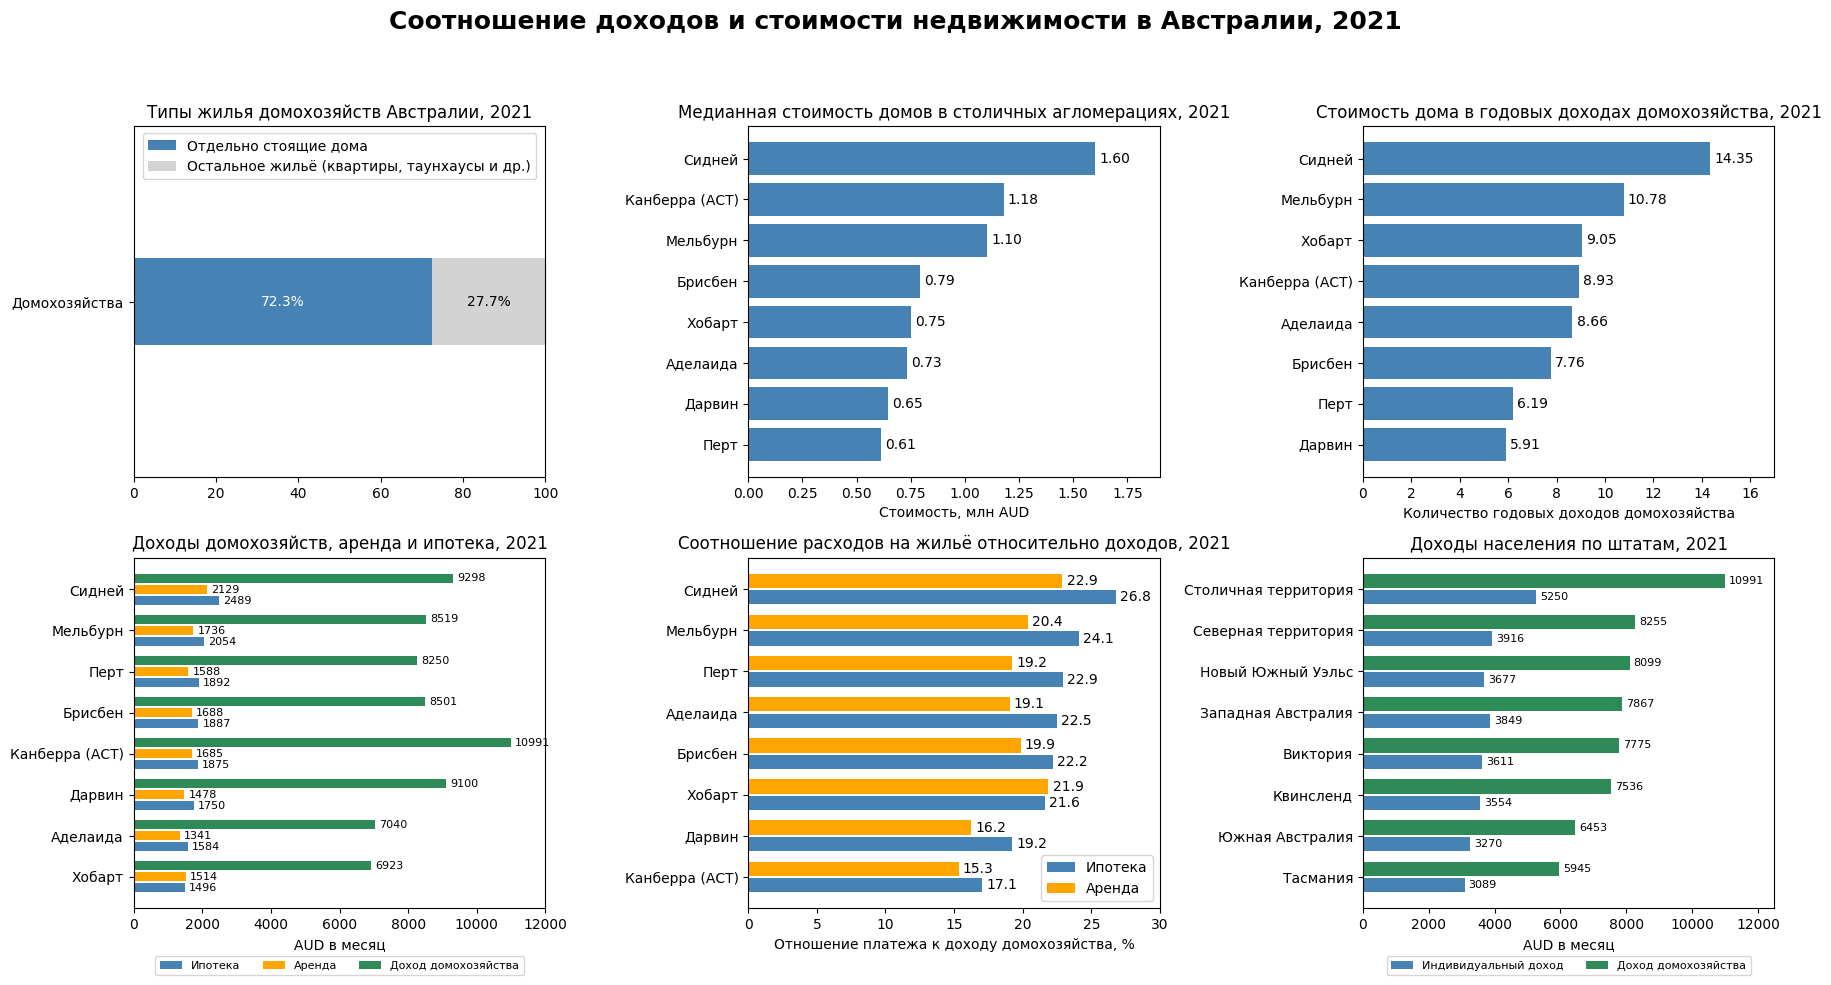

In [4291]:
### Типы жилья Австралии

fig, ax = plt.subplots(2,3,figsize=(18, 10))
ax[0,0].barh('Домохозяйства',detached_australia_pct,color='steelblue',height=0.5,label='Отдельно стоящие дома')
ax[0,0].barh('Домохозяйства',other_australia_pct,left=detached_australia_pct,color='lightgray',height=0.5,label='Остальное жильё (квартиры, таунхаусы и др.)')
ax[0,0].set_xlim(0,100)
ax[0,0].set_title('Типы жилья домохозяйств Австралии, 2021')
ax[0,0].text(detached_australia_pct/2,0, f'{detached_australia_pct:.1f}%',ha='center',va='center',color='white')
ax[0,0].text(detached_australia_pct + other_australia_pct/2, 0, f'{other_australia_pct:.1f}%',ha='center',va='center',color='black')
ax[0,0].set_ylim(-1, 1)
ax[0,0].legend(loc='upper center', fontsize=10)

### Стоимость жилья в Австралии в восьми столицах штатов

df_prices_plot = df_city_prices_2021.sort_values('house,AUD')

df_prices_plot['city_ru'] = df_prices_plot['GCCSA_NAME_2021'].map(city_names_ru)
ax[0,1].barh(df_prices_plot['city_ru'], df_prices_plot['house,AUD'] / 1000000,color='steelblue')
ax[0,1].set_title('Медианная стоимость домов в столичных агломерациях, 2021')
ax[0,1].set_xlabel('Стоимость, млн AUD')
ax[0,1].bar_label(ax[0,1].containers[0],fmt='%.2f',padding=3)
ax[0,1].set_xlim(0,1.9)

### Стоимость дома в годовых доходах домохозяйства, 2021

df_income_plot = df_capitals.sort_values('house_price_to_annual_hhd_income')
df_income_plot['city_ru'] = df_income_plot['GCCSA_NAME_2021'].map(city_names_ru)
ax[0,2].barh(df_income_plot['city_ru'], df_income_plot['house_price_to_annual_hhd_income'],color='steelblue')
ax[0,2].set_title('Стоимость дома в годовых доходах домохозяйства, 2021')
ax[0,2].set_xlabel('Количество годовых доходов домохозяйства')
ax[0,2].bar_label(ax[0,2].containers[0],fmt='%.2f',padding=3)
ax[0,2].set_xlim(0, 17)

### Доходы домохозяйств,аренда и ипотека

df_payments_plot = df_capitals.sort_values('mortgage_repay_monthly')
df_payments_plot['city_ru'] = df_payments_plot['GCCSA_NAME_2021'].map(city_names_ru)
y = np.arange(len(df_payments_plot))
ax[1,0].barh(y - 0.27, df_payments_plot['mortgage_repay_monthly'],height=0.23, color='steelblue', label='Ипотека')
ax[1,0].barh(y, df_payments_plot['rent_monthly'],height=0.23, color='orange', label='Аренда')
ax[1,0].barh(y + 0.27, df_payments_plot['hhd_inc_monthly'],height=0.23, color='seagreen', label='Доход домохозяйства')
ax[1,0].set_title('Доходы домохозяйств, аренда и ипотека, 2021')
ax[1,0].set_yticks(y, df_payments_plot['city_ru'])
ax[1,0].set_xlabel('AUD в месяц')
ax[1,0].legend(loc='upper center',bbox_to_anchor=(0.5, -0.12),ncol=3,fontsize=8)
ax[1,0].bar_label(ax[1, 0].containers[0], fmt='%.0f', padding=3, fontsize=8)
ax[1,0].bar_label(ax[1, 0].containers[1], fmt='%.0f', padding=3, fontsize=8)
ax[1,0].bar_label(ax[1, 0].containers[2], fmt='%.0f', padding=3, fontsize=8)
ax[1,0].set_xlim(0, 12000)

### Соотношение расходов на жильё относительно доходов
df_burden_plot = df_capitals.sort_values('mortgage_to_hhd_income_pct')
df_burden_plot['city_ru'] = df_burden_plot['GCCSA_NAME_2021'].map(city_names_ru)
y = range(len(df_burden_plot))
mortgage_bars = ax[1,1].barh([i - 0.2 for i in y],df_burden_plot['mortgage_to_hhd_income_pct'],height=0.35,color='steelblue',label='Ипотека')
rent_bars = ax[1,1].barh([i + 0.2 for i in y],df_burden_plot['rent_to_hhd_income_pct'],height=0.35,color='orange',label='Аренда')
ax[1,1].set_yticks(list(y))
ax[1,1].set_yticklabels(df_burden_plot['city_ru'])
ax[1,1].set_title('Соотношение расходов на жильё относительно доходов, 2021')
ax[1,1].set_xlabel('Отношение платежа к доходу домохозяйства, %')
ax[1,1].legend()
ax[1,1].bar_label(mortgage_bars,labels=[f'{v:.1f}' for v in df_burden_plot['mortgage_to_hhd_income_pct']],padding=3)
ax[1,1].bar_label(rent_bars,labels=[f'{v:.1f}' for v in df_burden_plot['rent_to_hhd_income_pct']],padding=3)
ax[1,1].set_xlim(0,30)

### Доходы населения по штатам Австралии

df_state_plot = df_state_income.drop(index='Other Territories').copy()

df_state_plot['state_ru'] = df_state_plot.index.map(state_names_ru)
df_state_plot = df_state_plot.sort_values('household_income_monthly')
y_state = range(len(df_state_plot))
ax[1,2].barh([i - 0.2 for i in y_state], df_state_plot['personal_income_monthly'],height=0.35,color='steelblue',label='Индивидуальный доход')
ax[1,2].barh([i + 0.2 for i in y_state],df_state_plot['household_income_monthly'],height=0.35,color='seagreen',label='Доход домохозяйства')
ax[1,2].set_yticks(list(y_state))
ax[1,2].set_yticklabels(df_state_plot['state_ru'])
ax[1,2].set_title('Доходы населения по штатам, 2021')
ax[1,2].set_xlabel('AUD в месяц')
ax[1,2].legend(loc='upper center',bbox_to_anchor=(0.5, -0.12),ncol=2,fontsize=8)
ax[1,2].bar_label(ax[1, 2].containers[0], fmt='%.0f', padding=3, fontsize=8)
ax[1,2].bar_label(ax[1, 2].containers[1], fmt='%.0f', padding=3, fontsize=8)
ax[1,2].set_xlim(0, 12500)

fig.suptitle('Соотношение доходов и стоимости недвижимости в Австралии, 2021',fontsize=18, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig('../visualizations/australia_housing_income_2021.png',dpi=300, bbox_inches='tight')

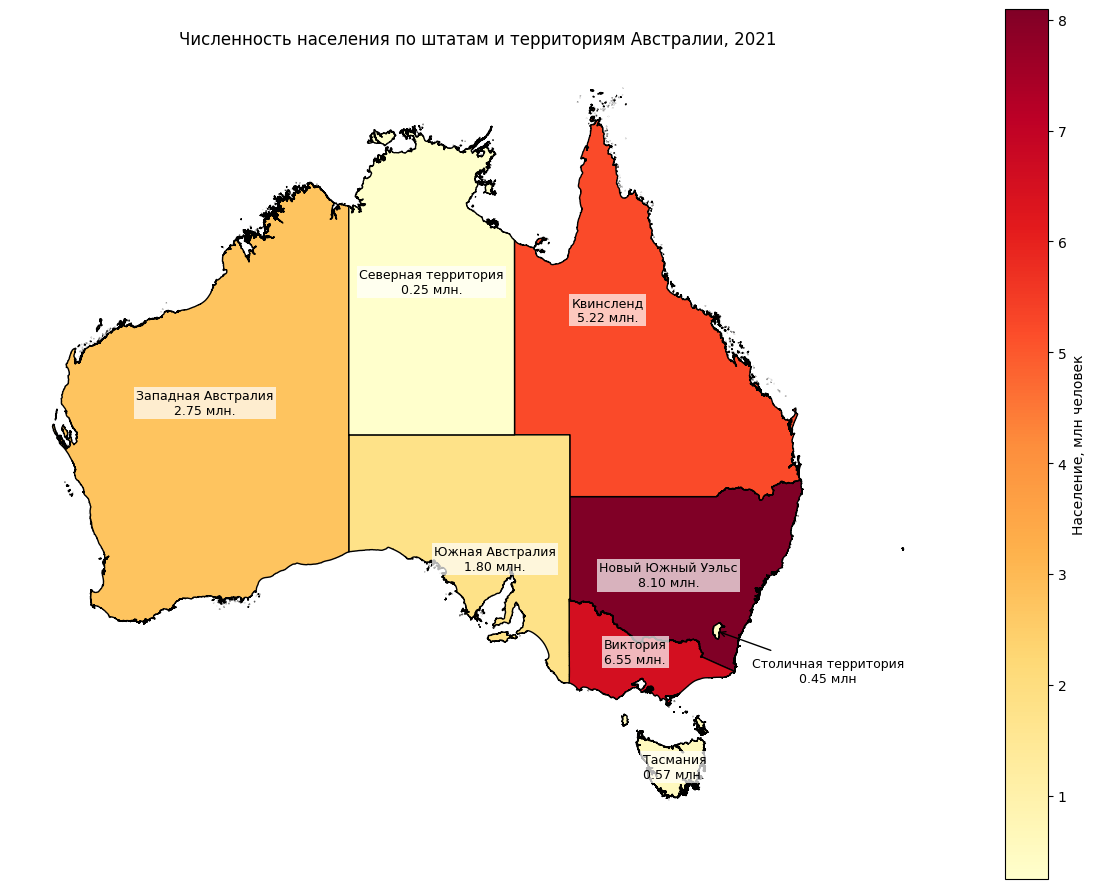

In [4292]:
### Численность населения по штатам и территориям Австралии, 2021

fig, ax = plt.subplots(figsize=(12, 9))

gdf_population[gdf_population['STE_NAME21'] != 'Other Territories'].plot(column='population_mln',
    cmap='YlOrRd',legend=True,edgecolor='black',linewidth=1,ax=ax,legend_kwds={'label': 'Население, млн человек'})

ax.set_title('Численность населения по штатам и территориям Австралии, 2021')
ax.set_axis_off()
for _, row in gdf_population.iterrows():
    state_en = row['STE_NAME21']
    if state_en in ['Other Territories', 'Australian Capital Territory']:
        continue
    x = row['label_point'].x
    y = row['label_point'].y
    pop_mln = row['total_population_state'] / 1_000_000
    label = f"{state_names_ru.get(state_en, state_en)}\n{pop_mln:.2f} млн."
    ax.text(x, y,label,ha='center',va='center',fontsize=9,bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1.5))

act = gdf_population[gdf_population['STE_NAME21'] == 'Australian Capital Territory'].iloc[0]

ax.annotate('Столичная территория\n0.45 млн',
    xy=(act['label_point'].x, act['label_point'].y),xytext=(155, -38),fontsize=9,ha='center',
    arrowprops=dict(arrowstyle='->', color='black'),bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
plt.tight_layout()
fig.savefig('../visualizations/australia_population_map_2021.png',dpi=300, bbox_inches='tight')

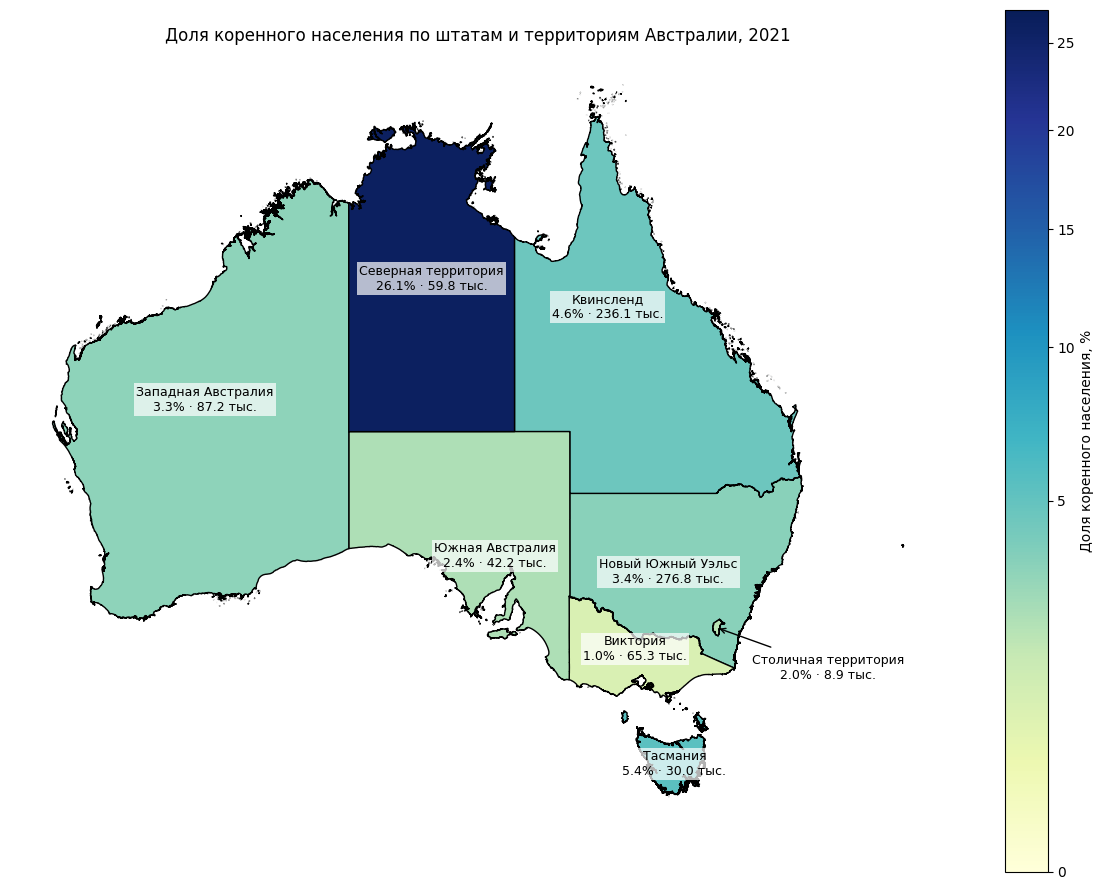

In [4288]:
### Распределение коренного населения

fig2, ax2 = plt.subplots(figsize=(12, 9))
gdf_indigenous[gdf_indigenous['STE_NAME21'] != 'Other Territories'].plot(column='indigenous_share_pct_st',cmap='YlGnBu',
    legend=True,legend_kwds={'label':'Доля коренного населения, %'},edgecolor='black',
    linewidth=1,ax=ax2,norm=PowerNorm(gamma=0.5, vmin=0, vmax=27),)
ax2.set_title('Доля коренного населения по штатам и территориям Австралии, 2021')
ax2.set_axis_off()
gdf_indigenous['label_point'] = gdf_indigenous.geometry.representative_point()

for _, row in gdf_indigenous.iterrows():
    state_en = row['STE_NAME21']
    if state_en in ['Other Territories', 'Australian Capital Territory']:
        continue
    x = row['label_point'].x
    y = row['label_point'].y
    pct = row['indigenous_share_pct_st']
    pop_thousand = row['indigenous_population_st'] / 1000
    label = f"{state_names_ru.get(state_en, state_en)}\n{pct:.1f}% · {pop_thousand:.1f} тыс."
    ax2.text(x, y, label,ha='center', va='center',fontsize=9,bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1.5)    )

act = gdf_indigenous[gdf_indigenous['STE_NAME21'] == 'Australian Capital Territory'].iloc[0]

ax2.annotate(f"Столичная территория\n{act['indigenous_share_pct_st']:.1f}% · {act['indigenous_population_st'] / 1000:.1f} тыс.",
    xy=(act['label_point'].x, act['label_point'].y),xytext=(155, -38),fontsize=9,ha='center',
    arrowprops=dict(arrowstyle='->', color='black'),bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

plt.tight_layout()
fig2.savefig('../visualizations/australia_indigenous_share_2021.png',dpi=300, bbox_inches='tight')

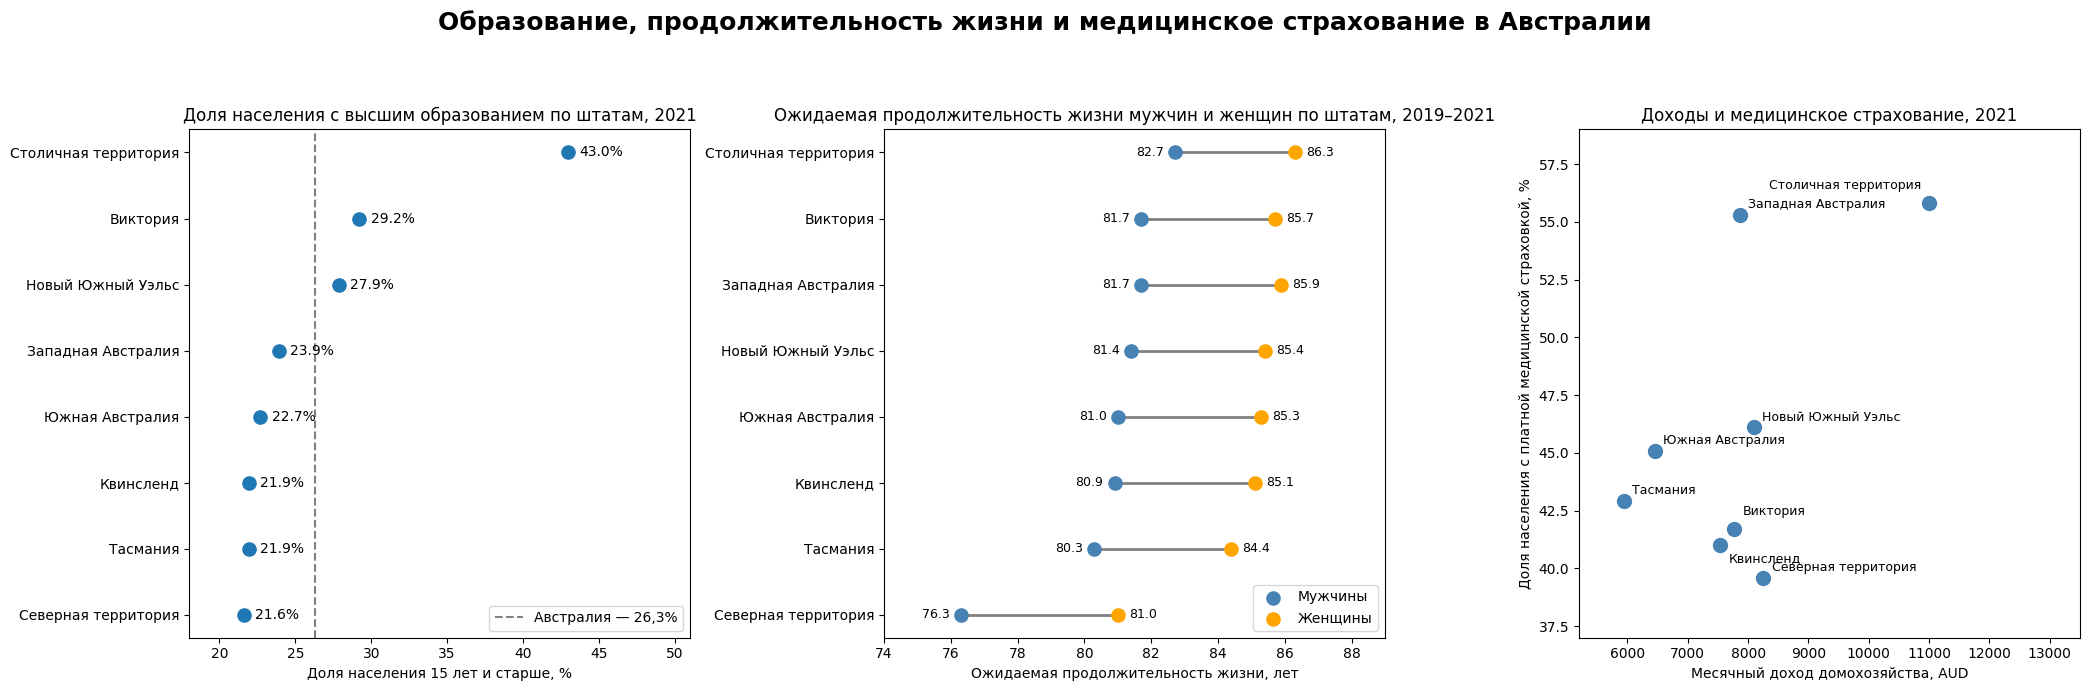

In [4289]:
### Образование, медицина в Австралии, 2021

df_education_plot = df_education.drop(index=['Other Territories', 'Australia']).copy()
df_education_plot = df_education_plot.sort_values('higher_education_pct', ascending=False)
df_education_plot['state_ru'] = df_education_plot.index.map(state_names_ru)

fig3, ax3 = plt.subplots(1, 3, figsize=(21, 7))

### Доля населения с высшим образованием по штатам Австралии, 2021
ax3[0].scatter(x=df_education_plot['higher_education_pct'],y=df_education_plot['state_ru'],s=90)
ax3[0].set_title('Доля населения с высшим образованием по штатам, 2021', fontsize=12)
ax3[0].set_xlabel('Доля населения 15 лет и старше, %')
ax3[0].invert_yaxis()
for state, pct in zip(df_education_plot['state_ru'],df_education_plot['higher_education_pct']):
    ax3[0].annotate(f'{pct:.1f}%',xy=(pct, state),xytext=(8, 0),textcoords='offset points', va='center',fontsize=10)
ax3[0].axvline(26.32, color='gray', linestyle='--',linewidth=1.5, label='Австралия — 26,3%')
ax3[0].legend(loc='lower right')
ax3[0].set_xlim(18, 51)

### Ожидаемая продолжительность жизни, 2019–2021
df_life_plot = df_life_state_select[df_life_state_select['STATE_NAME_2021'] != 'Australia'].copy()
df_life_plot = df_life_plot.sort_values('life_male', ascending=False)
df_life_plot['state_ru'] = df_life_plot['STATE_NAME_2021'].map(state_names_ru)
ax3[1].hlines(y=df_life_plot['state_ru'],
    xmin=df_life_plot['life_male'],xmax=df_life_plot['life_female'],colors='gray',linewidth=2,zorder=0)
ax3[1].scatter(df_life_plot['life_male'],df_life_plot['state_ru'],color='steelblue',s=90,label='Мужчины')
ax3[1].scatter(df_life_plot['life_female'],df_life_plot['state_ru'],color='orange',s=90,label='Женщины')
for state, value in zip(df_life_plot['state_ru'], df_life_plot['life_male']):
    ax3[1].annotate(f'{value:.1f}',xy=(value, state),xytext=(-8, 0),textcoords='offset points',ha='right',va='center',fontsize=9)
for state, value in zip(df_life_plot['state_ru'], df_life_plot['life_female']):
    ax3[1].annotate(f'{value:.1f}',xy=(value, state),xytext=(8, 0),textcoords='offset points',ha='left',va='center',fontsize=9)
ax3[1].legend(loc='lower right')
ax3[1].invert_yaxis()
ax3[1].set_title('Ожидаемая продолжительность жизни мужчин и женщин по штатам, 2019–2021', fontsize=12)
ax3[1].set_xlabel('Ожидаемая продолжительность жизни, лет')
ax3[1].set_xlim(74, 89)

### Медицинское страхование
df_health_income_plot = df_health_insurance.merge(   df_state_income[['household_income_monthly']],left_on='STATE_NAME_2021',right_index=True,how='inner')
df_health_income_plot['state_ru'] = df_health_income_plot['STATE_NAME_2021'].map(state_names_ru)
ax3[2].scatter(x=df_health_income_plot['household_income_monthly'],y=df_health_income_plot['private_insurance_pct'],s=100,color='steelblue')
for _, row in df_health_income_plot.iterrows():
    if row['STATE_NAME_2021'] == 'Australian Capital Territory':
        offset = (-5, 10)
        alignment = 'right'
    elif row['STATE_NAME_2021'] == 'Victoria':
        offset = (6, 10)
        alignment = 'left'
    elif row['STATE_NAME_2021'] == 'Queensland':
        offset = (6, -12)
        alignment = 'left'
    else:
        offset = (6, 5)
        alignment = 'left'

    ax3[2].annotate(row['state_ru'],
                    xy=(row['household_income_monthly'], row['private_insurance_pct']),
                    xytext=offset,
                    textcoords='offset points',
                    ha=alignment,fontsize=9)
ax3[2].set_title('Доходы и медицинское страхование, 2021', fontsize=12)
ax3[2].set_xlabel('Месячный доход домохозяйства, AUD')
ax3[2].set_ylabel('Доля населения с платной медицинской страховкой, %')
ax3[2].set_xlim(5200, 13500)
ax3[2].set_ylim(37, 59)
fig3.suptitle('Образование, продолжительность жизни и медицинское страхование в Австралии',fontsize=18,fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.92])
fig3.savefig('../visualizations/australia_education_health_2021.png',dpi=300, bbox_inches='tight')

## 6. Выводы и ограничения исследований

### Цель исследования

Целью исследования Австралии было выявление факторов устойчивого благополучия страны, а также косвенных признаков перспективного экономического развития страны в целом, основываясь на расчётных величинах, косвенно отражающих предпочтения жителей, вместо опросов общественного мнения.

### Выводы

Исследование показывает, что в Австралии преобладают отдельно стоящие дома.

Их доля составляет 72,3% от общего количества занятых частных жилищ (остальные — таунхаусы, квартиры и пр.).

Стоимость домов такого типа является высокой (в Сиднейской, Столичной и Мельбурнской агломерациях медианная стоимость превышает 1 млн австралийских долларов).

И тем не менее, более 70% занятых частных жилищ Австралии являются отдельно стоящими домами.

Таким образом, Австралия — страна с преобладанием отдельно стоящих домов, стоимость которых в крупных городах очень высока.

Для приобретения такого дома австралийцам потребуется сумма, соответствующая нескольким годовым доходам домохозяйства (от 5,9 до 14,4 годового дохода в исследованных агломерациях). Погашение ипотеки может занимать десятки лет.

Но, несмотря на это, австралийцы совершают очень дорогой выбор.

Это может говорить о высоком доверии к государству, его экономической, политической, правовой системе, а также о привлекательности климатических условий, сделавших инвестиции в дорогое жильё перспективными в долгосрочной перспективе.

Также распространённость отдельно стоящих дорогих домов может указывать на предпочтение семейной формы социальной жизни, нежели индивидуальной.

Доходы, как индивидуальные, так и доходы домохозяйств, существенно различаются по штатам. Также 44,9% жителей Австралии имеют дополнительную медицинскую страховку. Несмотря на то, что расчётная доля дохода, приходящаяся на оплату жилья, довольно высока, стоимость жилья (покупка, аренда или ипотека) остаётся существенной.

Продолжительность жизни в большинстве штатов довольно длительная (от 80,3 до 82,7 года у мужчин и от 84,4 до 86,3 года у женщин), однако в Северной территории продолжительность жизни заметно меньше (76,3 и 81,0 года для мужчин и женщин соответственно). Это совпадает с высокой долей коренного населения на данной территории — 26,1%. Возможными факторами различий могут быть физиологические особенности, климатические условия, доступность медицинской помощи и социально-экономические условия. Определить их влияние на основании проведённых расчётов нельзя.

Бакалавриат и магистратура в Австралии не являются преобладающей формой образования: доля жителей от 15 лет с высшим и последипломным образованием составляет 26,3%. При этом индивидуальные доходы находятся на заметном уровне. Это может косвенно указывать на достойную оплату труда работников без высшего образования в том числе, однако требует проверки доходов непосредственно по уровням образования.

Географическое распределение жителей по континенту неравномерно и может быть связано с климатическими условиями, близостью к столичным агломерациям и береговой зоне.

Наибольшая численность жителей наблюдается в Новом Южном Уэльсе, Виктории и Квинсленде. Наибольшая абсолютная численность коренного населения Австралии отмечена в Новом Южном Уэльсе и Квинсленде.

В то же время в процентном выражении коренное население наиболее представлено в Северной территории (26,1%).

### Ограничения исследования

1. Исследование основано преимущественно на данных 2021 года. Они позволяют выявлять особенности структуры жилищного фонда, доходов и социально-экономических показателей, но не доказывают причин возникновения этих особенностей и не позволяют самостоятельно прогнозировать экономическое развитие страны.

2. Доля отдельно стоящих домов характеризует существующий жилищный фонд среди занятых частных жилищ, а не объёмы нового строительства. Данные не содержат площади домов и не позволяют установить, сколько жителей сознательно предпочли данный тип жилья.

3. Стоимость недвижимости взята из отчёта Domain за IV квартал 2021 года. Данные о доходах, аренде и ипотечных платежах получены из переписи ABS 2021. Доходы по штатам и агломерациям рассчитаны путём агрегирования медианных показателей территорий SA2 и не являются официальными медианами соответствующих штатов или городов.

4. Соотношения стоимости жилья, арендных и ипотечных платежей с доходами являются расчётными показателями. Они не отражают фактическую финансовую нагрузку конкретных домохозяйств, поскольку доходы и жилищные платежи относятся к разным совокупностям населения. Индивидуальный доход включает не только заработную плату, но и другие источники доходов.

5. Наличие дополнительного медицинского страхования не позволяет определить стоимость страховки для каждого жителя, качество государственной медицины или причины приобретения страхового полиса.

6. Различия в продолжительности жизни и территориальном распределении коренного населения не позволяют установить причинно-следственную зависимость между этническим составом населения и состоянием здоровья. Для этого необходимы дополнительные медицинские, социально-экономические и демографические данные.

7. Гипотезы о доверии к экономической и правовой системе, предпочтении семейного образа жизни и привлекательности долгосрочных инвестиций основаны на косвенных показателях. Они представляют собой интерпретацию результатов исследования и требуют самостоятельной проверки.

